## Libraries

In [6]:
from sklearn.datasets import make_moons
from sklearn.cluster import DBSCAN
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

## Dataset

In [2]:
X, _ = make_moons(
    n_samples=500,
    noise=0.06,
    random_state=42
)

## Standarize

In [3]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

## Train Model

In [12]:
model = DBSCAN(
    eps=0.20,
    min_samples=5
)
labels = model.fit_predict(X_scaled)
print(labels)

[ 0  1  0  1  1  0  0  1  1  0  1  1  0  1  0  0  0  1  0  0  0  0  0  0
  1  0  0  1  1  0  0  0  0  1  1  0  0  1  1  1  0  1  0  1  1  1  1  1
  0  1  1  1  1  0  1  1  1  1  1  1  0  0  0  0  1  1  0  1  1  0  0  0
  0  0  0  0  0  1  0  0  1  1  0  1  0  1  1  0  0  0  0  0  0  0  0  0
  1  1  0  1  1  0  1  0  0  1  0  1  0  1  1  0  0  1  0  0  1  1  1  1
  1  1  0  1  1  1  0  1  1  0  1  1  0  0  1  1  1  1  1  0  1  1  0  1
  0  0  1  1  0  0  1  1  1  1  0  0  1  1  0  1  1  0  0  1  0  0  1  1
  0  1  1  1  0  1  1  1  0  1  1  0  0  1  0  0  0  1  0  1  1  1  0  0
  0  0  1  1  1  1  1  0  0  1  1  1  1  1  1  1  0  0  0  1  0  0  0  0
  0  1  0  1  0  0  1  1  1  0  1  0  0  1  1  1  0  1  0  0  0  1  1  1
  0  1  0  1  0  1  1  1  0  1  0  0  0  1  0  0  1  0  1  0  0  1  0  1
  1  1  0  1  0  1  1  1  1  0  0  0  0  0  0  1  0  1  0  1  1  0  0  0
  0  0  0  0  0  0  1  1  0  0  0  0  0  1  0  1  1  1  0  1  1  1  0  1
  0  0  1  0  0  1  0  0  1  0  1  0  1  0  1  1  1

## Plot the result

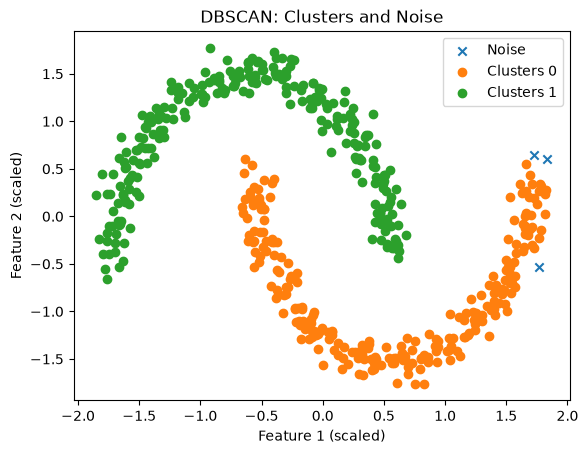

In [13]:
for label in np.unique(labels):
    mask = labels == label

    if label == -1:
        plt.scatter(
            X_scaled[mask, 0],
            X_scaled[mask, 1],
            label="Noise",
            marker='x'
        )
    else:
        plt.scatter(
            X_scaled[mask, 0],
            X_scaled[mask, 1],
            label=f"Clusters {label}"
        )

plt.title("DBSCAN: Clusters and Noise")
plt.xlabel("Feature 1 (scaled)")
plt.ylabel("Feature 2 (scaled)")
plt.legend()
plt.show()

## Inspect the result numerically

In [17]:
n_clusters = len(set(labels) - {-1})
n_noise = np.sum(labels == -1)

print("Clusters:", n_clusters)
print("Noise points:", n_noise)
print("Noise Percentage: ", round(100 * n_noise / len(labels), 2), "%")

Clusters: 2
Noise points: 3
Noise Percentage:  0.6 %
